# Week 1 · Day 5 · Task 1: Data Cleaning
**Goal:** clean the employee dataset from Day 4, document a decision for every column, and save `clean_data.csv`
plus a before/after summary (`reports/cleaning_summary.csv`).

The cleaning logic is in `src/cleaning.py`. This notebook calls those functions step by step and shows the
result of each step, so the notebook and the script always produce the same output.

In [1]:
from pathlib import Path
import sys

# Find this task's folder whether the notebook runs from notebooks/, the task folder or the repo root.
TASK = "task1_data_cleaning"
HERE = Path.cwd().resolve()
candidates = [p for base in [HERE, *HERE.parents]
              for p in (base, base / "week1" / "day5" / TASK)]
PROJECT_DIR = next(p for p in candidates if (p / "src" / "cleaning.py").is_file())
sys.path.insert(0, str(PROJECT_DIR / "src"))
print("Project folder:", PROJECT_DIR.name)

import pandas as pd
import matplotlib.pyplot as plt
import cleaning as c

Project folder: task1_data_cleaning


## 1. Load the original dataset
`data/employees.csv` is an unchanged copy of the Day 4 file.

In [2]:
df_raw = c.load_data(c.RAW_FILE)
df_raw

,id,name,department,salary,city
0,1,Arun,Sales,65000,Chennai
1,2,Priya,HR,45000,Bangalore
2,3,Karthik,IT,58000,chennai
3,4,Divya,IT,75000,Mumbai
4,5,Rohan,Finance,81000,CHENNAI
5,6,Meena,Sales,52000,Bangalore
6,7,Suresh,IT,68000,Hyderabad
7,8,Anitha,HR,48000,Mumbai


In [3]:
original_rows = len(df_raw)
print("Original row count:", original_rows)
print("Shape (rows, columns):", df_raw.shape)
df_raw.info()

Original row count: 8
Shape (rows, columns): (8, 5)
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          8 non-null      int64
 1   name        8 non-null      str  
 2   department  8 non-null      str  
 3   salary      8 non-null      int64
 4   city        8 non-null      str  
dtypes: int64(2), str(3)
memory usage: 452.0 bytes


## 2. Missing values per column

In [4]:
df_raw.isna().sum().rename("missing_values").to_frame()

,missing_values
id,0
name,0
department,0
salary,0
city,0


## 3. Duplicate rows
We check exact duplicate rows and repeated `id` values (the unique key).

In [5]:
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Repeated ids:      ", df_raw["id"].duplicated().sum())

Exact duplicate rows: 0
Repeated ids:       0


## 4. Inspect text values
`repr()` makes hidden leading/trailing spaces visible.

In [6]:
for col in c.TEXT_COLUMNS:
    print(f"{col:<11}", sorted(repr(v) for v in df_raw[col].unique()))

name        ["'Anitha'", "'Arun'", "'Divya'", "'Karthik'", "'Meena'", "'Priya'", "'Rohan'", "'Suresh'"]
department  ["'Finance'", "'HR'", "'IT'", "'Sales'"]
city        ["'Bangalore'", "'CHENNAI'", "'Chennai'", "'Hyderabad'", "'Mumbai'", "'chennai'"]


In [7]:
df_raw["city"].value_counts()

city
Bangalore    2
Mumbai       2
Chennai      1
chennai      1
CHENNAI      1
Hyderabad    1
Name: count, dtype: int64

**Finding:** there are no extra spaces, but `city` is written in three ways for one city
(`Chennai`, `chennai`, `CHENNAI`). Grouping by city before cleaning would split Chennai into three groups.

## 5. Standardise text
* `name`, `city`: trim spaces and use title case (`chennai` → `Chennai`).
* `department`: trim spaces. Acronyms stay upper case (`HR`, `IT`); other names use title case. Plain `.title()` would wrongly turn `IT` into `It`.
* `id` is **not** changed.

In [8]:
df_std = c.standardise_text(df_raw)
pd.DataFrame({"city_before": df_raw["city"], "city_after": df_std["city"]})

,city_before,city_after
0,Chennai,Chennai
1,Bangalore,Bangalore
2,chennai,Chennai
3,Mumbai,Mumbai
4,CHENNAI,Chennai
5,Bangalore,Bangalore
6,Hyderabad,Hyderabad
7,Mumbai,Mumbai


In [9]:
print("Distinct city values:", df_raw["city"].nunique(), "->", df_std["city"].nunique())
assert df_std["id"].equals(df_raw["id"]), "ids must not change"

Distinct city values: 6 -> 4


## 6. Fix data types
| Column | Before | After | Why |
|---|---|---|---|
| `id` | int64 | Int64 | Validated as a whole number. The nullable type would keep a missing id visible. |
| `salary` | int64 | int64 | Converted with `pd.to_numeric`. Text such as `"65,000"` would also be converted. |
| `department`, `city` | text | category | Few repeated labels. This saves memory and makes them clear grouping keys. |
| `name` | text | string | Free text. |

The dataset has no date column, so no date conversion is needed.

In [10]:
df_typed = c.fix_data_types(df_std)
pd.DataFrame({"before": df_raw.dtypes.astype(str), "after": df_typed.dtypes.astype(str)})

,before,after
id,int64,Int64
name,str,string
department,str,category
salary,int64,Int64
city,str,category


## 7. Handle missing values: one rule per column
The rules are defined in `cleaning.MISSING_VALUE_RULES`. **In this dataset no column has missing values**, so no
value is changed. The rules are still written down so the same script is safe to use on future data.

In [11]:
df_filled, missing_actions = c.handle_missing_values(df_typed)
pd.set_option("display.max_colwidth", None)
pd.DataFrame(missing_actions)

,column,missing_before,strategy,reason
0,id,0,drop,"The unique key. A row without an id cannot be identified or de-duplicated, and an id must never be invented."
1,name,0,flag,A personal name cannot be guessed; leave it empty and add a name_was_missing flag.
2,department,0,flag,Filling with the mode would put an employee in the wrong department and distort every department average; leave empty and flag.
3,city,0,flag,Filling with the mode would move an employee to the wrong city and distort city averages; leave empty and flag.
4,salary,0,median,"Numeric and the main measure. A gap is filled with the median of the same department (the median is not pulled by outliers), and a salary_was_imputed flag is added so imputed values stay visible."


## 8. Remove duplicates
This runs *after* text standardisation, so `' chennai'` and `'Chennai'` count as the same value.

In [12]:
df_dedup = c.remove_duplicates(df_filled)
print("Rows before:", len(df_filled), "| after:", len(df_dedup), "| removed:", len(df_filled) - len(df_dedup))

Rows before: 8 | after: 8 | removed: 0


## 9. Outliers: IQR rule
`id` is an identifier, not a measurement, so only `salary` is checked.
A value is an outlier if it is below **Q1 − 1.5 × IQR** or above **Q3 + 1.5 × IQR**.

In [13]:
salary = df_dedup["salary"]
q1, q3 = salary.quantile(0.25), salary.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df_dedup[(salary < lower) | (salary > upper)]
print(f"Q1 = {q1:,.0f} | Q3 = {q3:,.0f} | IQR = {iqr:,.0f}")
print(f"Lower bound = {lower:,.0f} | Upper bound = {upper:,.0f}")
print("Outlier count (salary):", len(outliers))

Q1 = 51,000 | Q3 = 69,750 | IQR = 18,750
Lower bound = 22,875 | Upper bound = 97,875
Outlier count (salary): 0


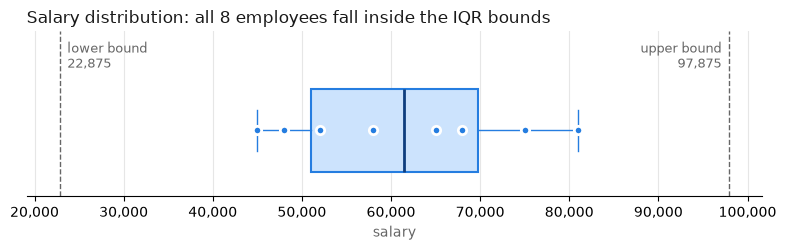

In [14]:
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.boxplot(salary, orientation="horizontal", widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#cce3fd", edgecolor="#257de0", linewidth=1.5),
           medianprops=dict(color="#0e3d7e", linewidth=2),
           whiskerprops=dict(color="#257de0"), capprops=dict(color="#257de0"))
ax.scatter(salary, [1] * len(salary), s=36, color="#257de0", edgecolor="white", linewidth=2, zorder=3)
for x, label, side in [(lower, "lower bound", "left"), (upper, "upper bound", "right")]:
    ax.axvline(x, color="#666666", linestyle="--", linewidth=1)
    offset = 800 if side == "left" else -800
    ax.text(x + offset, 1.45, f"{label}\n{x:,.0f}", ha=side, va="center", fontsize=9, color="#666666")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title("Salary distribution: all 8 employees fall inside the IQR bounds", loc="left", color="#191919")
ax.set_yticks([]); ax.set_xlabel("salary", color="#666666")
ax.set_ylim(0.6, 1.6)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.grid(axis="x", color="#e6e6e6", linewidth=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

**Decision:** no salary is outside the bounds. The lowest salary (45,000) and the highest (81,000) are well within them,
so **nothing is removed or changed**. Even if an outlier were found, the script only **flags** it (`salary_outlier` column),
because a very high or low salary can be real (a senior or junior role). Only impossible values (for example negative pay)
would be removed, and only after checking with the data owner.

In [15]:
df_flagged, outlier_results = c.flag_outliers(df_dedup)
pd.DataFrame(outlier_results)

,q1,q3,iqr,lower_bound,upper_bound,outlier_count,column,treatment
0,51000.0,69750.0,18750.0,22875.0,97875.0,0,salary,No outliers found - nothing changed.


## 10. Full pipeline, save `clean_data.csv` and the before/after summary

In [16]:
df_clean, details = c.clean(df_raw)
assert df_clean.equals(df_flagged), "pipeline result must match the step-by-step result"

df_clean.to_csv(c.CLEAN_FILE, index=False)
details["summary"].to_csv(c.SUMMARY_FILE, index=False)
b, a = details["before"], details["after"]
print(f"Rows {b['rows']} -> {a['rows']} | Missing values {b['missing_values']} -> {a['missing_values']} "
      f"| Duplicates {b['duplicate_rows']} -> {a['duplicate_rows']}")
df_clean

Rows 8 -> 8 | Missing values 0 -> 0 | Duplicates 0 -> 0


,id,name,department,salary,city,salary_outlier
0,1,Arun,Sales,65000,Chennai,False
1,2,Priya,HR,45000,Bangalore,False
2,3,Karthik,IT,58000,Chennai,False
3,4,Divya,IT,75000,Mumbai,False
4,5,Rohan,Finance,81000,Chennai,False
5,6,Meena,Sales,52000,Bangalore,False
6,7,Suresh,IT,68000,Hyderabad,False
7,8,Anitha,HR,48000,Mumbai,False


In [17]:
details["summary"]

,metric,before,after,decision_or_note
0,Rows,8,8,Rows removed only for duplicates or a missing id.
1,Missing values (all cells),0,0,Each column follows its documented missing-value rule.
2,Exact duplicate rows,0,0,Checked again after text standardisation.
3,Duplicate ids,0,0,id is the unique key.
4,Distinct city values,6,4,Chennai / chennai / CHENNAI were one city written three ways.
5,salary IQR outliers,0,0,"Q1=51,000, Q3=69,750, IQR=18,750, bounds [22,875, 97,875]. No outliers found - nothing changed."


## Conclusion
* Rows: **8 → 8**. No row needed to be removed.
* Missing values: **0 → 0**. Duplicate rows and duplicate ids: **0 → 0**.
* The one real problem was **city letter case**: 6 spellings became 4 real cities (Chennai, Bangalore, Mumbai, Hyderabad).
* Salary outliers (IQR): **0**, so all salaries are kept.
* Limitation: 8 rows is a very small sample. The value of this task is the documented, reusable cleaning process.

Next step: `../../task2_exploratory_analysis/notebooks/exploratory_analysis.ipynb`.